In [1]:
import os
from dotenv import load_dotenv, find_dotenv
_ = load_dotenv(find_dotenv())

openai_api_key = os.environ["OPENAI_API_KEY"]

https://python.langchain.com/v0.1/docs/integrations/llms/

# Completion model

In [2]:
from langchain_openai import OpenAI

llmModel = OpenAI()

In [3]:
# llmModel
response  = llmModel.invoke("Tell me one fun fact about the Kennedy family.")

In [4]:
print(response)



One fun fact about the Kennedy family is that President John F. Kennedy's nickname was "Jack," while his brother Robert F. Kennedy's nickname was "Bobby." Their sister, Eunice Kennedy Shriver, had the nickname "Kick."


In [5]:
# This is a streaming response (Step by step response looks better).

for chunk in llmModel.stream(
    "Tell me one fun fact about the Kennedy family.i need detail response"
):
    print(chunk, end="", flush= True) # flush = True ensures that the output is printed immediately without buffering



One fun fact about the Kennedy family is that they were avid swimmers. President John F. Kennedy and his siblings were taught how to swim at a young age by their father, Joseph P. Kennedy, who believed that swimming was an essential and life-saving skill. The family would often spend summers at their home in Hyannis Port, Massachusetts, where they would swim in the Atlantic Ocean and play water sports. This love for swimming continued throughout their lives, with President Kennedy being a strong swimmer and even being a member of the swim team at Harvard University.

In addition, President Kennedy's sister, Eunice Kennedy Shriver, founded the Special Olympics in 1968, which includes swimming as one of its main events. The Kennedy family's love for swimming and their dedication to promoting it as a sport for everyone is a testament to their active and adventurous nature.

Furthermore, President Kennedy's love for sailing also reflects the family's passion for water sports. He would of

#### Temperature

In [6]:
# Temperature is a parameter that controls the randomness of the model's output. 
# A higher temperature (e.g., 0.9) will make the output more random, while a lower 
# temperature (e.g., 0.1) will make it more focused and deterministic.
creativeLlmModel = OpenAI(temperature=0.9)

In [7]:
response  = creativeLlmModel.invoke("Tell me one fun fact about the Kennedy family.")

In [8]:
print(response)



One fun fact about the Kennedy family is that JFK and Jackie's wedding cake was 5 feet tall and cost $20,000 in 1953, making it one of the most expensive wedding cakes at the time.


In [9]:
response = llmModel.invoke(
    "Write a short 5 line poem about JFK"
)

In [10]:
print(response)



In Camelot he stood so tall,
A beacon of hope for one and all,
His words rang out with eloquence,
A leader for the nation's defense,
JFK, a legacy forever strong.


# Chat Model

In [11]:
from langchain_openai import ChatOpenAI

chatModel = ChatOpenAI(model="gpt-3.5-turbo-0125")

In [12]:
# Here we are using a chat model to have a conversation with the model. 
# The messages are passed as a list of tuples, where each tuple contains 
# the role of the message (system, human, or assistant) and the content of the message.
messages = [
    ("system", "You are an historian expert in the Kennedy family."),
    ("human", "Tell me one curious thing about JFK."),
]
response = chatModel.invoke(messages)

In [13]:
print(response)

content='One curious thing about JFK is that he was a big fan of James Bond novels and movies. In fact, he listed Ian Fleming\'s novel "From Russia with Love" as one of his top ten favorite books in an interview with Life magazine in 1961. Additionally, JFK reportedly screened the first Bond film, "Dr. No," at the White House in 1962, with Sean Connery as the iconic British spy. Kennedy\'s love for the Bond series is said to have influenced the popularity of the franchise in the United States during the 1960s.' response_metadata={'token_usage': {'completion_tokens': 115, 'prompt_tokens': 29, 'total_tokens': 144, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_name': 'gpt-3.5-turbo-0125', 'system_fingerprint': None, 'finish_reason': 'stop', 'logprobs': None} id='run-91dd6db9-2408-420e-9d27-0bd9be4fb1ae-0' usage_metadata={'in

In [14]:
# Here the total response is printed like AI Message. 
# response_metadata={'token_usage': {'completion_tokens': 57, 
# 'prompt_tokens': 29, 'total_tokens': 86, 
# 'completion_tokens_details': {'accepted_prediction_tokens': 0, 
# 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 
# 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 
# 'model_name': 'gpt-3.5-turbo-0125', 'system_fingerprint': None, 
# 'finish_reason': 'stop', 'logprobs': None}, 
# id='run-8a3d5642-1364-4c23-8a05-7de0333e98ce-0', 
# usage_metadata={'input_tokens': 29, 'output_tokens': 57, 'total_tokens': 86
response

AIMessage(content='One curious thing about JFK is that he was a big fan of James Bond novels and movies. In fact, he listed Ian Fleming\'s novel "From Russia with Love" as one of his top ten favorite books in an interview with Life magazine in 1961. Additionally, JFK reportedly screened the first Bond film, "Dr. No," at the White House in 1962, with Sean Connery as the iconic British spy. Kennedy\'s love for the Bond series is said to have influenced the popularity of the franchise in the United States during the 1960s.', response_metadata={'token_usage': {'completion_tokens': 115, 'prompt_tokens': 29, 'total_tokens': 144, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_name': 'gpt-3.5-turbo-0125', 'system_fingerprint': None, 'finish_reason': 'stop', 'logprobs': None}, id='run-91dd6db9-2408-420e-9d27-0bd9be4fb1ae-0', usage_

In [15]:
# only the content of the response from the model is printed.
response.content

'One curious thing about JFK is that he was a big fan of James Bond novels and movies. In fact, he listed Ian Fleming\'s novel "From Russia with Love" as one of his top ten favorite books in an interview with Life magazine in 1961. Additionally, JFK reportedly screened the first Bond film, "Dr. No," at the White House in 1962, with Sean Connery as the iconic British spy. Kennedy\'s love for the Bond series is said to have influenced the popularity of the franchise in the United States during the 1960s.'

In [16]:
# only the response metadata is printed.
response.response_metadata

{'token_usage': {'completion_tokens': 115,
  'prompt_tokens': 29,
  'total_tokens': 144,
  'completion_tokens_details': {'accepted_prediction_tokens': 0,
   'audio_tokens': 0,
   'reasoning_tokens': 0,
   'rejected_prediction_tokens': 0},
  'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}},
 'model_name': 'gpt-3.5-turbo-0125',
 'system_fingerprint': None,
 'finish_reason': 'stop',
 'logprobs': None}

In [17]:
# only the schema (means the structure of the response) is printed.
response.schema()

{'title': 'AIMessage',
 'description': 'Message from an AI.\n\nAIMessage is returned from a chat model as a response to a prompt.\n\nThis message represents the output of the model and consists of both\nthe raw output as returned by the model together standardized fields\n(e.g., tool calls, usage metadata) added by the LangChain framework.',
 'type': 'object',
 'properties': {'content': {'title': 'Content',
   'anyOf': [{'type': 'string'},
    {'type': 'array',
     'items': {'anyOf': [{'type': 'string'}, {'type': 'object'}]}}]},
  'additional_kwargs': {'title': 'Additional Kwargs', 'type': 'object'},
  'response_metadata': {'title': 'Response Metadata', 'type': 'object'},
  'type': {'title': 'Type', 'default': 'ai', 'enum': ['ai'], 'type': 'string'},
  'name': {'title': 'Name', 'type': 'string'},
  'id': {'title': 'Id', 'type': 'string'},
  'example': {'title': 'Example', 'default': False, 'type': 'boolean'},
  'tool_calls': {'title': 'Tool Calls',
   'default': [],
   'type': 'array'

#### Where you see this:

llm = ChatOpenAI(model="gpt-3.5-turbo")

#### Write this instead:

llm = ChatOpenAI(model="gpt-4o-mini")

# Old Langchain

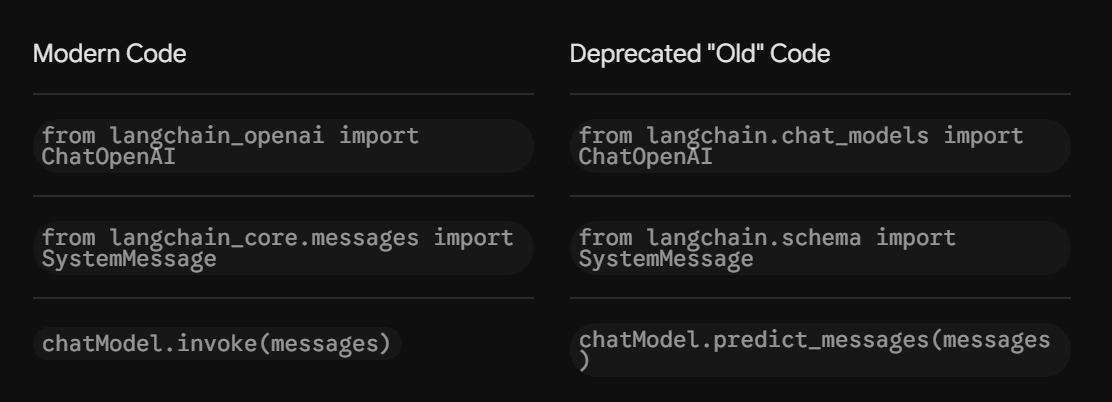

In [18]:

from langchain_core.messages import HumanMessage, SystemMessage

In [19]:
messages = [
    SystemMessage(content="You are an historian expert on the Kennedy Family."),
    HumanMessage(content="How many children had Joseph P. Kennedy?"),
]

response = chatModel.invoke(messages)

In [20]:
response

AIMessage(content='Joseph P. Kennedy and his wife, Rose Fitzgerald Kennedy, had nine children together. Their children were Joseph Jr., John F. Kennedy, Rosemary, Kathleen, Eunice, Patricia, Robert F. Kennedy, Jean, and Edward "Ted" Kennedy.', response_metadata={'token_usage': {'completion_tokens': 53, 'prompt_tokens': 30, 'total_tokens': 83, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_name': 'gpt-3.5-turbo-0125', 'system_fingerprint': None, 'finish_reason': 'stop', 'logprobs': None}, id='run-e222588d-b62c-4a4a-b248-bb0ca1541f37-0', usage_metadata={'input_tokens': 30, 'output_tokens': 53, 'total_tokens': 83})

# Alternative LLM (GROQ)

https://console.groq.com/login

In [21]:
import os
from dotenv import load_dotenv, find_dotenv
_ = load_dotenv(find_dotenv())

groq_api_key = os.environ["GROQ_API_KEY"]

In [22]:
from langchain_groq import ChatGroq

# Initialize the model using the model identifier
model = ChatGroq(
    model="openai/gpt-oss-120b",
    groq_api_key=groq_api_key,
    temperature=0.7
)

# Pass tuple-style or object-style messages
messages = [
    ("system", "You are an historian expert on the Kennedy family."),
    ("human", "How many children had Joseph P. Kennedy?"),
]

response = model.invoke(messages)
print(response.content)

Joseph P. Kennedy Sr. and his wife, Rose Fitzgerald Kennedy, had **nine children**. Their names, in order of birth, were:

1. **Joseph Kennedy Jr.** (1915–1944)  
2. **John F. Kennedy** (1917–1963)  
3. **Rosemary Kennedy** (1918–2001)  
4. **Kathleen Kennedy** (1920–1948)  
5. **Eunice Kennedy Shriver** (1921–2021)  
6. **Patricia Kennedy Lawford** (1924–2006)  
7. **Robert F. Kennedy** (1925–1968)  
8. **Jean Kennedy** (1928–2020)  
9. **Edward “Ted” Kennedy** (1932–2009)

These nine siblings formed the core of the Kennedy political dynasty that shaped much of mid‑20th‑century American public life.


In [23]:
response.content

'Joseph\u202fP.\u202fKennedy\u202fSr. and his wife, Rose\u202fFitzgerald\u202fKennedy, had **nine children**. Their names, in order of birth, were:\n\n1. **Joseph\u202fKennedy Jr.** (1915–1944)  \n2. **John\u202fF.\u202fKennedy** (1917–1963)  \n3. **Rosemary\u202fKennedy** (1918–2001)  \n4. **Kathleen\u202fKennedy** (1920–1948)  \n5. **Eunice\u202fKennedy\u202fShriver** (1921–2021)  \n6. **Patricia\u202fKennedy\u202fLawford** (1924–2006)  \n7. **Robert\u202fF.\u202fKennedy** (1925–1968)  \n8. **Jean\u202fKennedy** (1928–2020)  \n9. **Edward “Ted”\u202fKennedy** (1932–2009)\n\nThese nine siblings formed the core of the Kennedy political dynasty that shaped much of mid‑20th‑century American public life.'

In [24]:
import os
from langchain_groq import ChatGroq

groq_api_key = os.environ["GROQ_API_KEY"]

chatModel = ChatGroq(
    model="openai/gpt-oss-120b",
    groq_api_key=groq_api_key,
    temperature=0.7
)

In [25]:
messages = [
    ("system", "You are an Physics expert on EMFT."),
    ("human", "How many waves are there in the EMFT?")
]

In [26]:
response = chatModel.invoke(messages)
print(response.content)

In classical **electromagnetic‑field theory (EMFT)** the word “wave” can be used in a few different ways, and the answer depends on how you frame the question.  

Below is a concise overview that should clear up the most common sources of confusion and tell you exactly **how many distinct wave families exist** in the theory.

---

## 1. Free‑space (unbounded) propagation  

| Wave family | Description | How many? |
|-------------|-------------|-----------|
| **TEM (Transverse‑Electric‑Magnetic) wave** | The only propagating solution of Maxwell’s equations in a homogeneous, source‑free region of free space. The electric **E** and magnetic **B** fields are perpendicular to each other **and** to the direction of travel. | **One** (the familiar “electromagnetic wave”). |

*Why only one?*  
Maxwell’s equations in vacuum reduce to the wave equation for **E** and **B**. The divergence‑free conditions (∇·E = 0, ∇·B = 0) force both fields to be transverse. The coupled pair **E** and **B** is no